<a href="https://colab.research.google.com/github/YanuarRamadhaniKuswoko/PCVK_Sem5/blob/main/Pertemuan7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## TUGAS PRAKTIKUM
D1. Tugas Individu

Langkah 1.Import folder yang ada di Drive Anda

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Langkah 2.Import beberapa library berikut

In [3]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3.Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan
threshold= 200, secara manual sehingga menghasilkan tampilan seperti berikut:

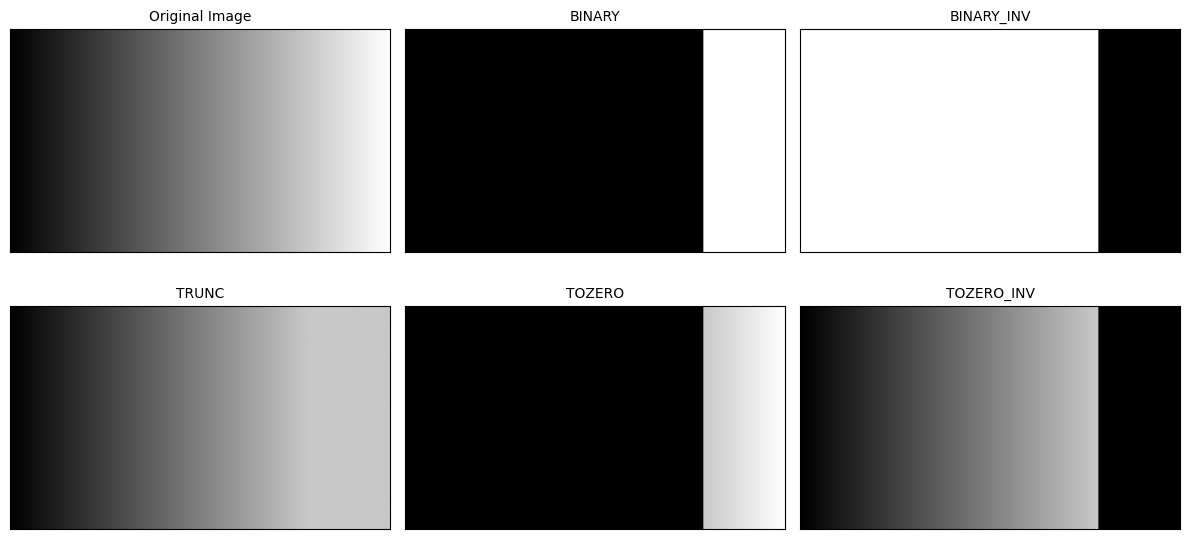

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Membuat gradien gambar dari hitam ke putih (0 sampai 255)
# Membuat array 1D bernilai 0 sampai 255 dengan rentang gradien
img = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (150, 1))

thresh = 200
max_val = 255

# 2. Implementasi Global Thresholding secara Manual berdasarkan ketentuan
# BINARY: Jika > thresh menjadi max_val, else 0
binary = np.where(img > thresh, max_val, 0).astype(np.uint8)

# BINARY_INV: Jika > thresh menjadi 0, else max_val
binary_inv = np.where(img > thresh, 0, max_val).astype(np.uint8)

# TRUNC: Jika > thresh menjadi thresh, else tetap nilai asli
trunc = np.where(img > thresh, thresh, img).astype(np.uint8)

# TOZERO: Jika > thresh tetap nilai asli, else 0
tozero = np.where(img > thresh, img, 0).astype(np.uint8)

# TOZERO_INV: Jika > thresh menjadi 0, else tetap nilai asli
tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

# 3. Menampilkan hasil dalam grid 2x3
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(12, 6))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i], fontsize=10)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

4.Buat program Addaptive Threshold : adaptive mean dan adaptive Gaussian tanpa
menggunakan cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter siap
pakai dengan menggunakan citra Sudoku yang memiliki pencahayaan tidak merata.
Ketentuan: global threshold secara manual dengan ambang 127, ukuran jendela 11 ×
11, C=2, dan sigma=2 untuk Gaussian sehingga menghasilkan tampilan seperti
berikut:

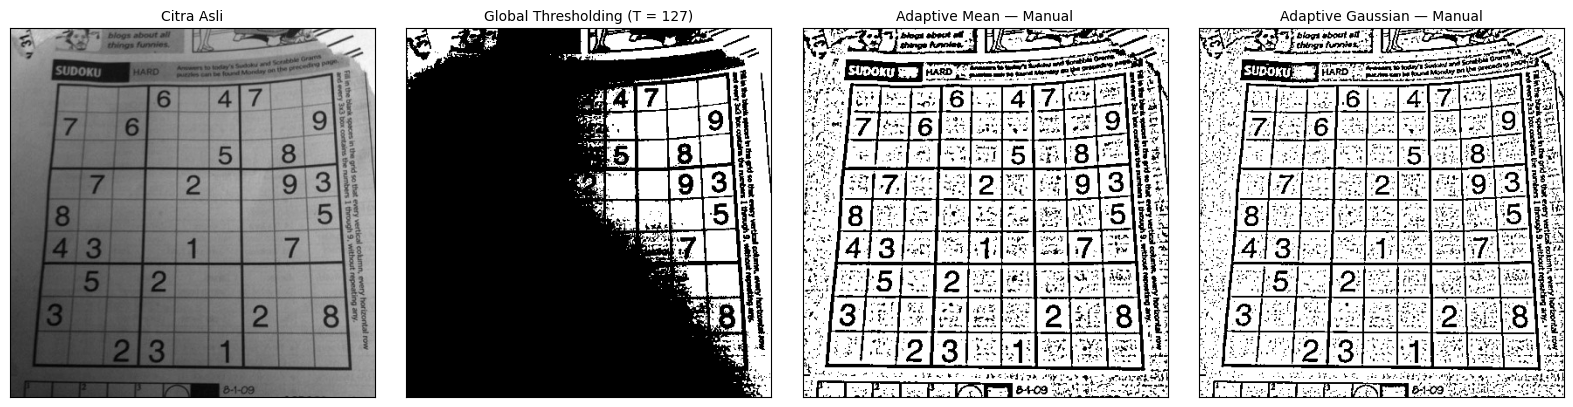

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Menentukan path file gambar
# Ganti path sesuai letak file Anda (misal di Drive atau upload langsung)
filename = '/content/drive/MyDrive/PCVK/sudoku-original.jpg'

# Membaca gambar dalam mode Grayscale
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

# Jika gambar tidak ditemukan, beri penanganan error
if img is None:
    raise FileNotFoundError(f"File tidak ditemukan pada path: {filename}. Harap periksa kembali path atau upload gambarnya.")

# Parameter sesuai ketentuan soal
thresh = 127
window_size = 11
C = 2
sigma = 2

# 2. Global Thresholding Manual (T = 127)
global_thresh = np.where(img > thresh, 255, 0).astype(np.uint8)

# Padding citra dengan mode reflect
pad = window_size // 2
padded_img = np.pad(img.astype(np.float64), pad, mode='reflect')

# 3. Adaptive Mean Thresholding Manual
mean_kernel = np.ones((window_size, window_size), dtype=np.float64) / (window_size * window_size)

local_mean = np.zeros_like(img, dtype=np.float64)
h, w = img.shape

for i in range(h):
    for j in range(w):
        region = padded_img[i:i + window_size, j:j + window_size]
        local_mean[i, j] = np.sum(region * mean_kernel)

adaptive_mean = np.where(img > (local_mean - C), 255, 0).astype(np.uint8)

# 4. Adaptive Gaussian Thresholding Manual
x = np.arange(-pad, pad + 1)
y = np.arange(-pad, pad + 1)
x_grid, y_grid = np.meshgrid(x, y)
gaussian_kernel = np.exp(-(x_grid**2 + y_grid**2) / (2 * sigma**2))
gaussian_kernel /= np.sum(gaussian_kernel)

local_gaussian = np.zeros_like(img, dtype=np.float64)

for i in range(h):
    for j in range(w):
        region = padded_img[i:i + window_size, j:j + window_size]
        local_gaussian[i, j] = np.sum(region * gaussian_kernel)

adaptive_gaussian = np.where(img > (local_gaussian - C), 255, 0).astype(np.uint8)

# 5. Menampilkan Hasil (Grid 1x4)
titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
images = [img, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(16, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontsize=10)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

5.A. Buat Otsu Thresholding tanpa menggunakan Library. Tampilkan juga nilai threshold saat anda gunakan Otsu’s, seperti terlihat pada gambar hasil berikut. (gunakan image lena_gs_lc2.jpg untuk dibandingkan dengan hasil dengan penggunaan library.

B. Kemudian coba dengan image KTP sendiri agar terlihat beda antara hasil otsu’s
dengan global threshold biasa)

/tmp/ipykernel_2956/2588564015.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_2956/2588564015.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


93


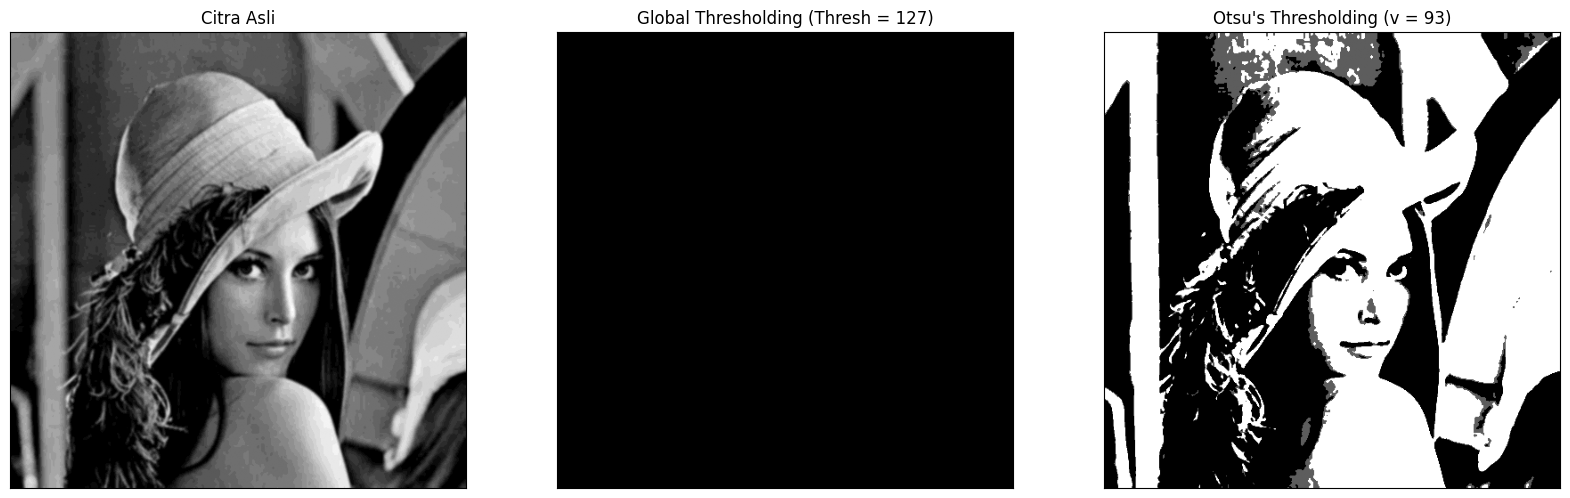

In [4]:
filename = ('/content/drive/MyDrive/PCVK/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

Pertanyaan: Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?
Hasil dengan KTP_Fulan (Bandingkan dengan hasil yang diperoleh)

-Penyebab Hitam Semua: Nilai threshold manual (127) terlalu tinggi untuk citra Lena yang gelap/kontras rendah (lc2), sehingga seluruh piksel yang nilainya di bawah 127 diubah menjadi 0 (hitam).

-Angka Ambang Batas (Thresh) Ideal: Berkisar antara 30 sampai 60 (atau menggunakan hasil otomatis dari algoritma Otsu) agar detail gambar Lena mulai terlihat.

-Perbandingan dengan KTP_Fulan: Citra KTP memiliki perbedaan kontras yang tajam (bimodal) antara latar belakang terang dan teks gelap, sehingga global thresholding dengan angka 127 biasanya langsung berhasil memisahkan teks dengan jelas.

Hasil dengan KTP_Fulan (Bandingkan dengan hasil yang diperoleh)

/tmp/ipykernel_2956/3064329543.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


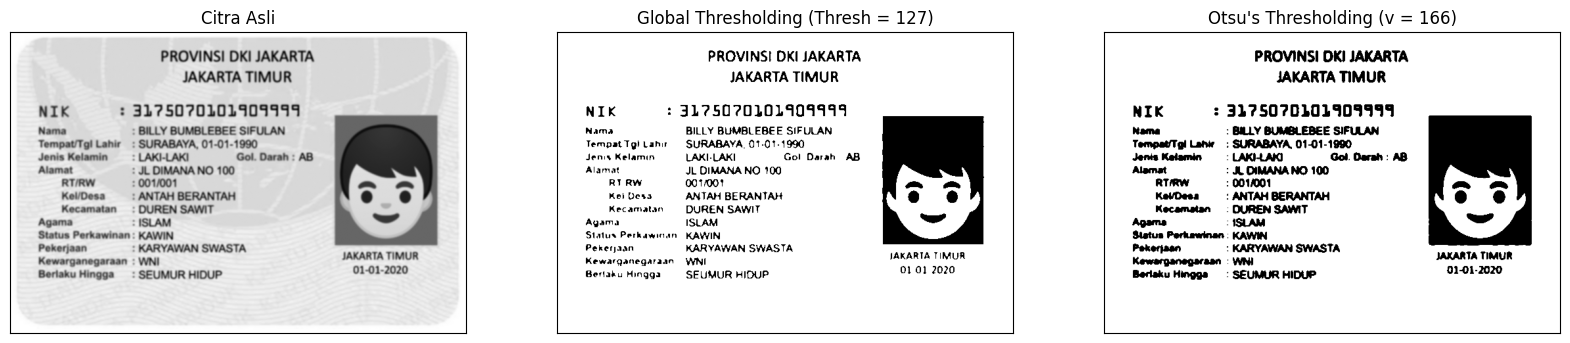

In [5]:
filename = ('/content/drive/MyDrive/PCVK/ktp_fulan.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

6. A. Lakukan Segmentasi Berbasis Region pada citra data.coins() dari skimage.

Citra ini cocok karena memuat objek yang jelas (koin), latar yang cukup homogen,
dan beberapa koin yang saling bersentuhan. Ketentuan:

• Tentukan 3 seed: satu di dalam koin, satu di latar, dan satu tepat di tepi koin.

• Jalankan dengan T = 5, 20, dan 60.

• Tampilkan hasilnya dalam grid 3×3 (seed × T)

Hasil yang diharapkan (Jumlah piksel belum tentu sama persis dengan contoh):

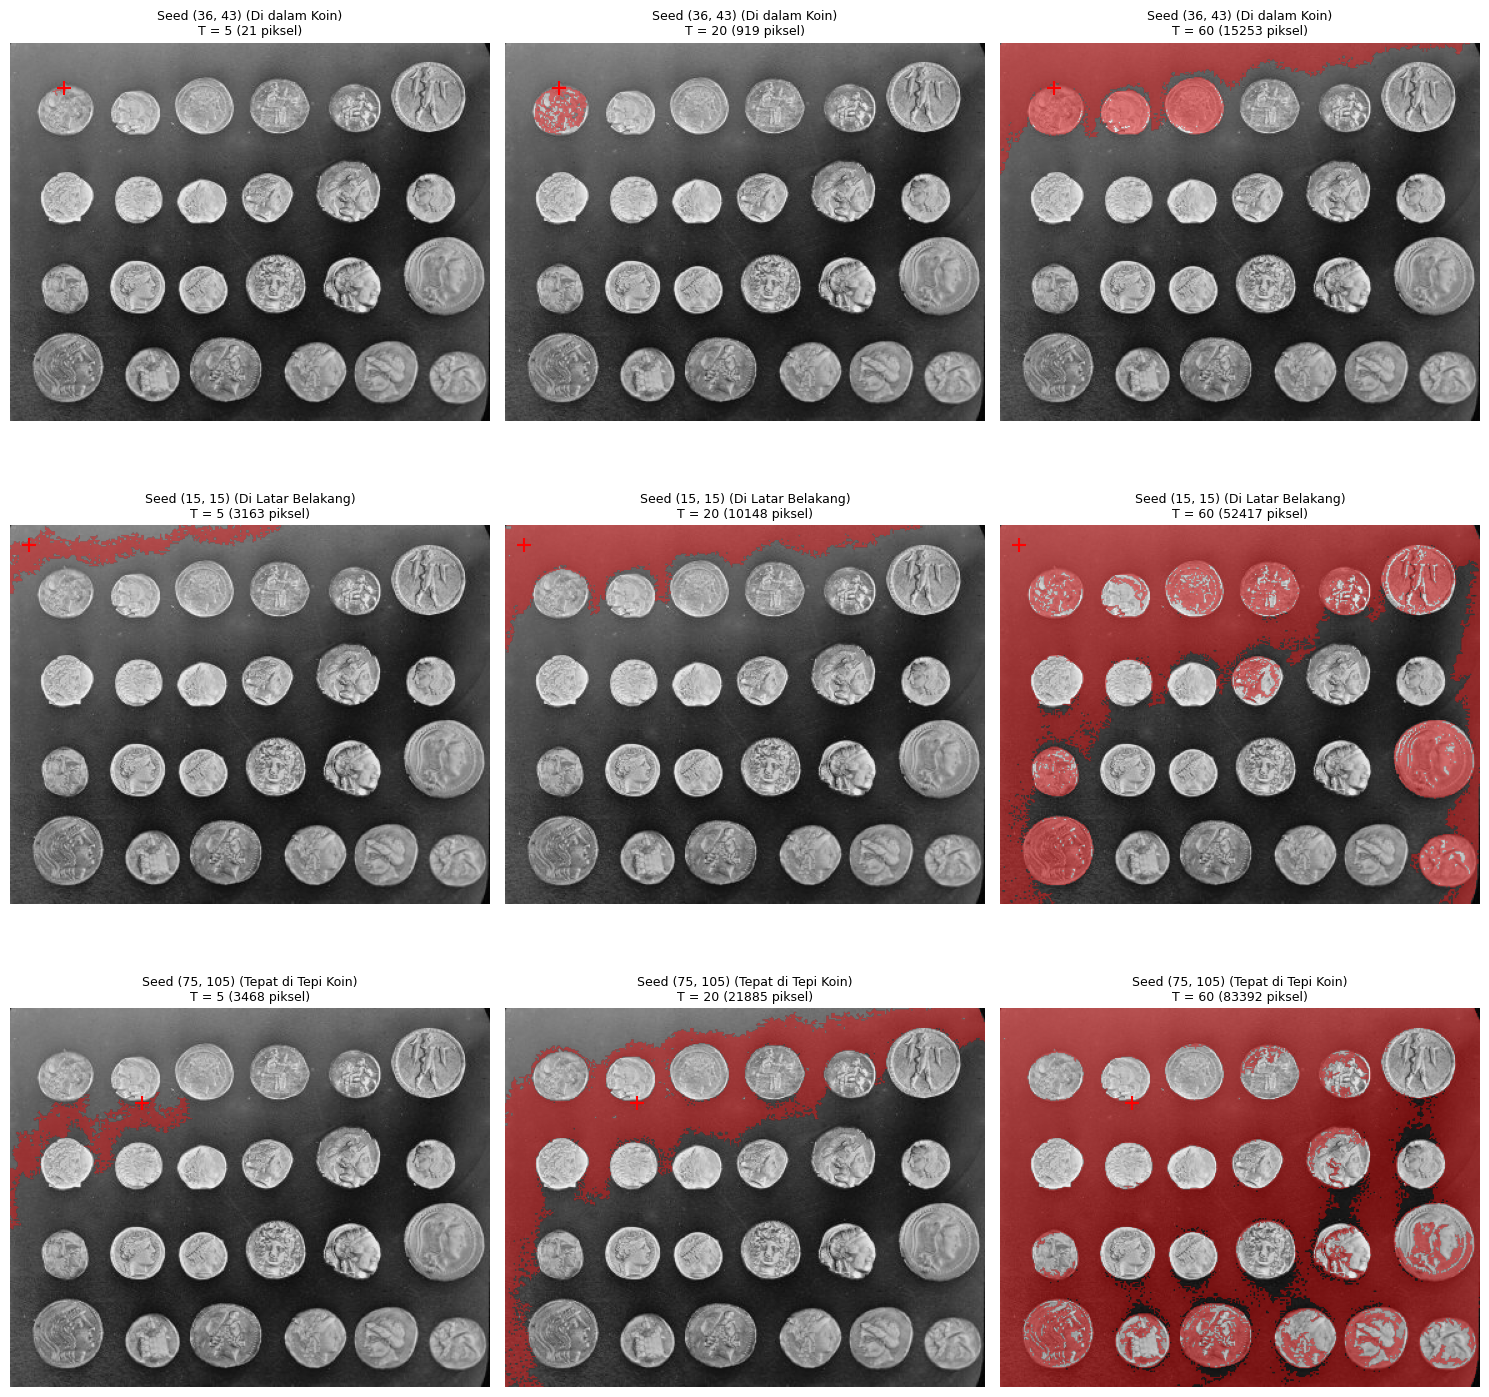

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

# 1. Memuat citra coins
img = data.coins()  # grayscale, ukuran 303 x 384
height, width = img.shape

# 2. Menentukan 3 titik seed (baris, kolom) sesuai ketentuan:
# - Seed 1: Di dalam koin
# - Seed 2: Di latar belakang (background)
# - Seed 3: Tepat di tepi koin
seeds = [(36, 43), (15, 15), (75, 105)]
seed_labels = ['Di dalam Koin', 'Di Latar Belakang', 'Tepat di Tepi Koin']

# 3. Menentukan nilai Threshold (T)
thresholds = [5, 20, 60]


# Fungsi implementasi Region Growing
def region_growing(image, seed, T):
  row, col = seed
  seed_val = float(image[row, col])
  h, w = image.shape
  segmented = np.zeros((h, w), dtype=bool)
  visited = np.zeros((h, w), dtype=bool)

  queue = [(row, col)]
  visited[row, col] = True

  while queue:
    r, c = queue.pop(0)
    if abs(float(image[r, c]) - seed_val) <= T:
      segmented[r, c] = True
      for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < h and 0 <= nc < w and not visited[nr, nc]:
          visited[nr, nc] = True
          if abs(float(image[nr, nc]) - seed_val) <= T:
            queue.append((nr, nc))
  return segmented


# 4. Membuat Grid 3x3 (Seed x T)
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for i, seed in enumerate(seeds):
  for j, T in enumerate(thresholds):
    # Jalankan algoritma region growing
    seg = region_growing(img, seed, T)
    pixel_count = np.sum(seg)

    # Tampilkan citra grayscale asli sebagai background
    axes[i, j].imshow(img, cmap='gray')

    # Buat overlay warna merah transparan untuk area tersegmentasi
    overlay = np.zeros((*img.shape, 4))
    overlay[seg] = [1, 0, 0, 0.4]  # Merah dengan transparansi
    axes[i, j].imshow(overlay)

    # Tandai posisi seed dengan tanda silang merah
    axes[i, j].scatter(seed[1], seed[0], color='red', marker='+', s=100)

    # Judul subplot
    axes[i, j].set_title(
        f'Seed {seed} ({seed_labels[i]})\nT = {T} ({pixel_count} piksel)',
        fontsize=9,
    )
    axes[i, j].axis('off')

plt.tight_layout()
plt.show()

B. Gunakan skimage.segmentation.flood(). Fungsi ini menghasilkan mask region dari
seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam
toleransi terhadap intensitas seed.

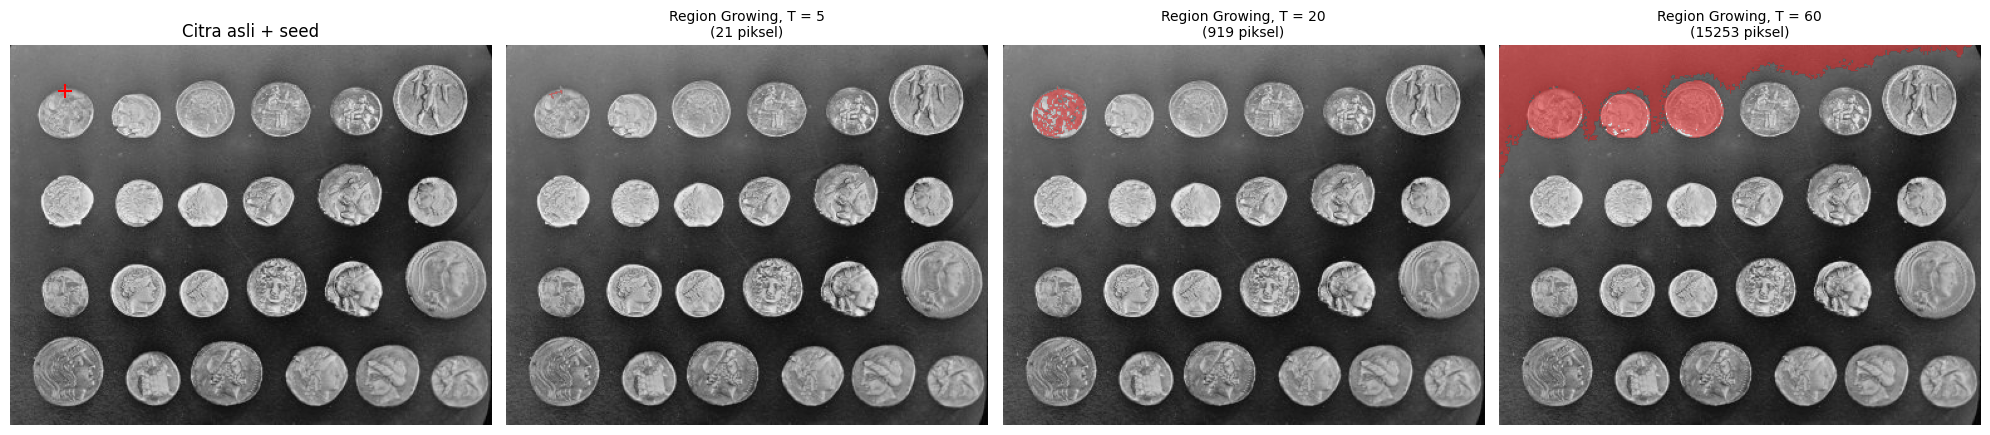

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data
from skimage.segmentation import flood

# 1. Memuat citra coins
img = data.coins()

# 2. Menentukan titik seed dan nilai toleransi (T)
# Menggunakan seed yang sama seperti pada contoh modul (baris, kolom): (36, 43)
seed = (36, 43)
thresholds = [5, 20, 60]

# 3. Membuat Grid 1x4 (Citra asli + seed, dan 3 nilai T)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Subplot 1: Citra asli + titik seed
axes[0].imshow(img, cmap='gray')
axes[0].scatter(seed[1], seed[0], color='red', marker='+', s=100)
axes[0].set_title('Citra asli + seed')
axes[0].axis('off')

# Subplot 2-4: Flood filling dengan toleransi 5, 20, dan 60
for j, T in enumerate(thresholds):
  # Menggunakan fungsi flood dari skimage.segmentation
  segmented = flood(img, seed_point=seed, tolerance=T, connectivity=1)
  pixel_count = np.sum(segmented)

  # Tampilkan citra grayscale asli
  axes[j + 1].imshow(img, cmap='gray')

  # Buat overlay warna merah transparan untuk area mask/region hasil flood
  overlay = np.zeros((*img.shape, 4))
  overlay[segmented] = [1, 0, 0, 0.4]  # Merah dengan transparansi
  axes[j + 1].imshow(overlay)

  # Judul subplot sesuai format pada modul
  axes[j + 1].set_title(
      f'Region Growing, T = {T}\n({pixel_count} piksel)', fontsize=10
  )
  axes[j + 1].axis('off')

plt.tight_layout()
plt.show()

7. Lakukan segmentasi warna pada image ktp_fulan.jpg , munculkan hanya warna yang
biru saja. (Petunjuk: anda dapat gunakan K-Means untuk menampilkan hanya warna
tertentu saja).
Rentang mencakup biru muda kebiruan pada latar KTP (dengan warna HSV):
kelompok_biru = np.where( (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40) )

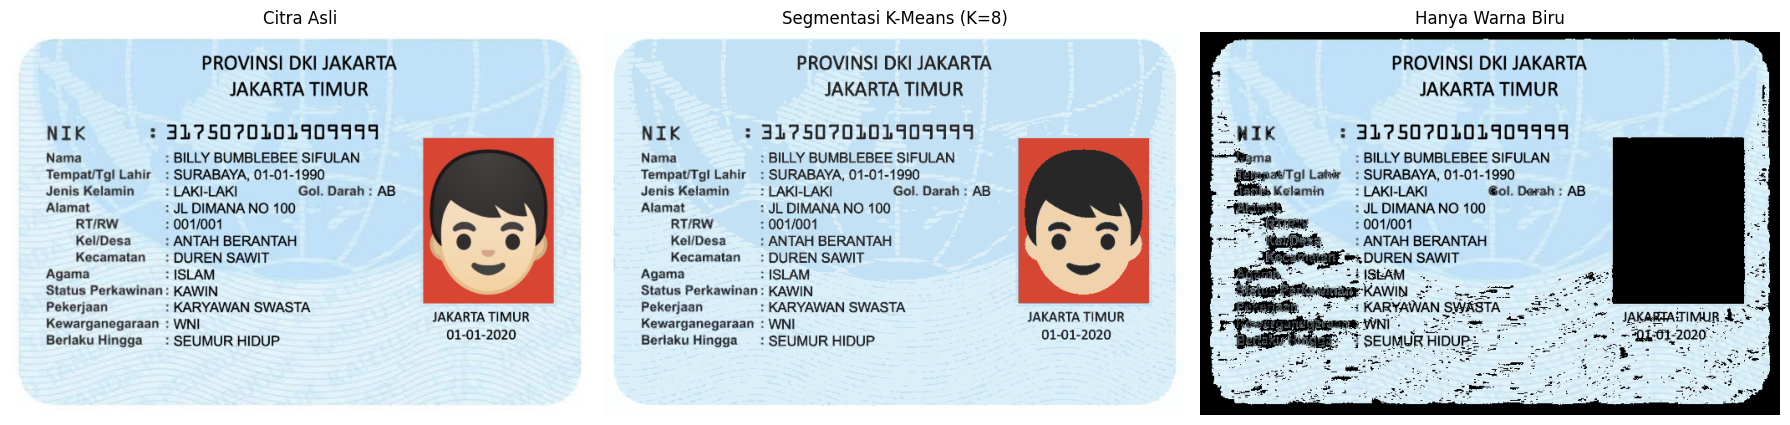

In [12]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Tentukan path file citra KTP Fulan di sini
path = '/content/drive/MyDrive/PCVK/ktp_fulan.jpg'

# 1. Memuat citra KTP Fulan
img = cv2.imread(path)

if img is None:
  print(
      f"Error: File dengan path '{path}' tidak ditemukan! Pastikan path atau"
      ' nama file sudah benar.'
  )
else:
  img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

  # 2. Konversi dari RGB ke HSV
  hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
  H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

  # 3. Menentukan rentang warna biru sesuai petunjuk soal
  kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

  # 4. Membuat mask dan citra hasil segmentasi (hanya warna biru)
  mask = np.zeros(img.shape[:2], dtype=np.uint8)
  mask[kelompok_biru] = 255

  # Mengatur agar area di luar warna biru menjadi hitam (seperti contoh soal)
  hanya_biru = cv2.bitwise_and(img_rgb, img_rgb, mask=mask)
  # Jika ingin latar belakang luar yang bukan biru menjadi hitam total:
  hanya_biru[mask == 0] = [
      0,
      0,
      0,
  ]  # Latar hitam, teks/elemen selain biru ikut hitam

  # 5. K-Means clustering (K=8)
  pixel_vals = img_rgb.reshape((-1, 3))
  pixel_vals = np.float32(pixel_vals)
  criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
  k = 8
  _, labels, centers = cv2.kmeans(
      pixel_vals, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS
  )
  centers = np.uint8(centers)
  segmented_data = centers[labels.flatten()]
  kmeans_img = segmented_data.reshape(img_rgb.shape)

  # 6. Menampilkan dalam grid 1x3 agar rapi dan bersih
  fig, axes = plt.subplots(1, 3, figsize=(18, 6))

  axes[0].imshow(img_rgb)
  axes[0].set_title('Citra Asli')
  axes[0].axis('off')

  axes[1].imshow(kmeans_img)
  axes[1].set_title('Segmentasi K-Means (K=8)')
  axes[1].axis('off')

  axes[2].imshow(hanya_biru)
  axes[2].set_title('Hanya Warna Biru')
  axes[2].axis('off')

  plt.tight_layout()
  plt.show()